# Lab 8 — K-Means

**Phần thực hành — Nguyễn Đình Huy — 2474802010140**

Mỗi mục/bài là một cell code. Chạy từ trên xuống; hình được lưu vào `figures/`. Dùng `scripts/run_all.py` để lưu thêm nhật ký TXT vào `outputs/`.

## Mục 2 — Tự viết K-Means

Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
  cum 1: A
  cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
  cum 1: A, B
  cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
  cum 1: A, B
  cum 2: C, D, E, F, G
  Tam khong doi nua, dung.

Inertia tu tinh: 8.5250


Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


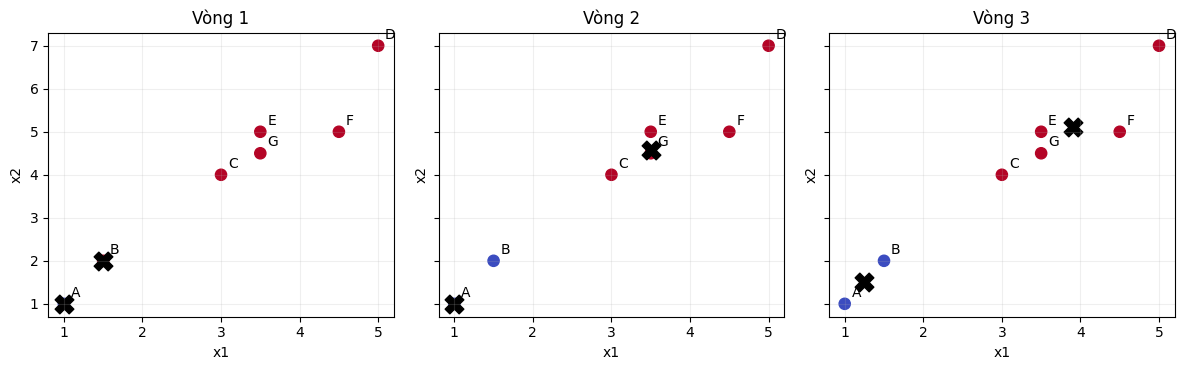

In [1]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Giữ thuật toán và bảy điểm của thầy; lưu lịch sử để vẽ sau khi chạy.
P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]
lich_su = []

def k_means(X, tam, so_vong_toi_da=10):
    """Gán điểm vào tâm gần nhất rồi dời tâm về trung bình cụm."""
    for vong in range(1, so_vong_toi_da + 1):
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        lich_su.append((tam.copy(), nhan.copy()))
        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cum {k + 1}: {', '.join(ds)}")
        tam_moi = np.array([X[nhan == k].mean(axis=0) for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tam khong doi nua, dung.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan

tam, nhan = k_means(P, P[[0, 1]].copy())
print()
inertia = ((P - tam[nhan]) ** 2).sum()
print(f"Inertia tu tinh: {inertia:.4f}")
km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())
fig, axes = plt.subplots(1, len(lich_su), figsize=(12, 3.8), sharex=True, sharey=True)
for vong, (ax, (tam_vong, nhan_vong)) in enumerate(zip(axes, lich_su), 1):
    ax.scatter(P[:, 0], P[:, 1], c=nhan_vong, cmap="coolwarm", s=65)
    ax.scatter(tam_vong[:, 0], tam_vong[:, 1], marker="X", s=180, c="black", label="Tâm đầu vòng")
    for ten, p in zip(TEN, P):
        ax.annotate(ten, p, xytext=(5, 5), textcoords="offset points")
    ax.set(title=f"Vòng {vong}", xlabel="x1", ylabel="x2")
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.savefig(thu_muc_hinh / "kmeans_tung_vong.png", dpi=150)
plt.show()


## Mục 3 — Phân khúc khách hàng

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.3       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.8           22.0
50%     39.0      17.4           49.0
75%     46.0      28.6           77.0
max     62.0      35.5           99.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.4
3       8.0           18.9        40     44.9
4      30.2           81.5        40     32.6

Inertia: 23.02

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 4
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 0


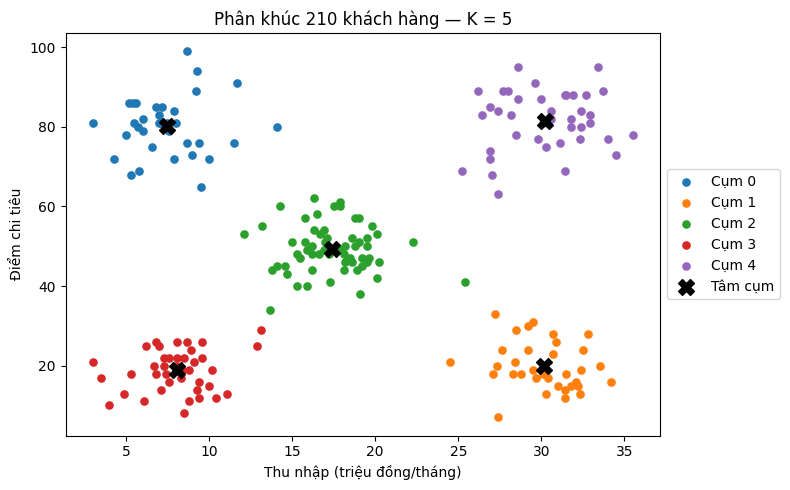

In [2]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv(tep_du_lieu("khach_hang.csv"))
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())
print()
X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=X.columns)
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("Tam cum, don vi goc:")
print(tam.round(1).to_string())
print(f"\nInertia: {km.inertia_:.2f}\n")
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0], "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]}, chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")
fig, ax = plt.subplots(figsize=(8, 5))
for k in range(5):
    nhom = df[df["cum"] == k]
    ax.scatter(nhom.thu_nhap, nhom.diem_chi_tieu, label=f"Cụm {k}", s=27)
ax.scatter(tam.thu_nhap, tam.diem_chi_tieu, marker="X", c="black", s=130, label="Tâm cụm")
ax.set(xlabel="Thu nhập (triệu đồng/tháng)", ylabel="Điểm chi tiêu", title="Phân khúc 210 khách hàng — K = 5")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.savefig(thu_muc_hinh / "phan_khuc_khach_hang.png", dpi=150)
plt.show()


## Mục 4 — Chọn số cụm K

 K  inertia  giam so voi K-1  silhouette
  1    420.0                             
  2    250.4            169.6       0.430
  3    152.5             97.9       0.522
  4     73.8             78.8       0.626
  5     23.0             50.7       0.723
  6     20.9              2.1       0.651


  7     19.0              1.9       0.541
  8     17.4              1.6       0.454
  9     15.9              1.5       0.471
 10     14.4              1.4       0.425


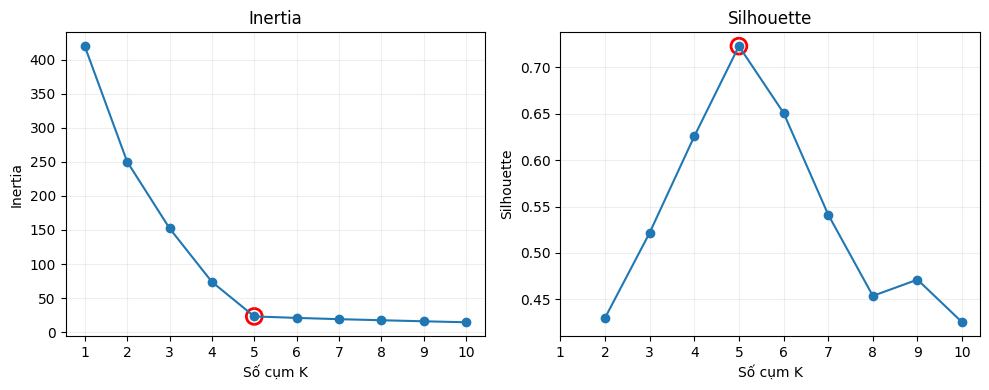

In [3]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv(tep_du_lieu("khach_hang.csv"))
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])
print(" K  inertia  giam so voi K-1  silhouette")
truoc = None
inertias, silhouettes = [], []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    sil = "" if k == 1 else f"{silhouette_score(Xs, km.labels_):.3f}"
    print(f" {k:2d}  {km.inertia_:7.1f}  {giam:>15s}  {sil:>10s}")
    truoc = km.inertia_
    inertias.append(km.inertia_)
    silhouettes.append(np.nan if k == 1 else silhouette_score(Xs, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, scores, title in zip(axes, [inertias, silhouettes], ["Inertia", "Silhouette"]):
    ax.plot(range(1, 11), scores, "o-")
    ax.scatter([5], [scores[4]], s=130, facecolors="none", edgecolors="red", linewidths=2)
    ax.set(xlabel="Số cụm K", ylabel=title, title=title, xticks=range(1, 11))
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.savefig(thu_muc_hinh / "chon_k.png", dpi=150)
plt.show()


## Mục 5 — Ba cái bẫy của K-Means

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
  (  6.1,  52.5)
  (  9.6,  41.9)
  ( 17.4,  49.8)
  ( 27.8,  52.9)
  ( 31.9,  52.4)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
  [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
  [72.4, 73.6, 73.7, 73.7, 84.0, 84.2, 84.2, 116.6, 117.4, 118.2]
  Voi n_init=10: inertia 23.0

Bay 3: hai vang trang, ty le khop nhan that 0.7500


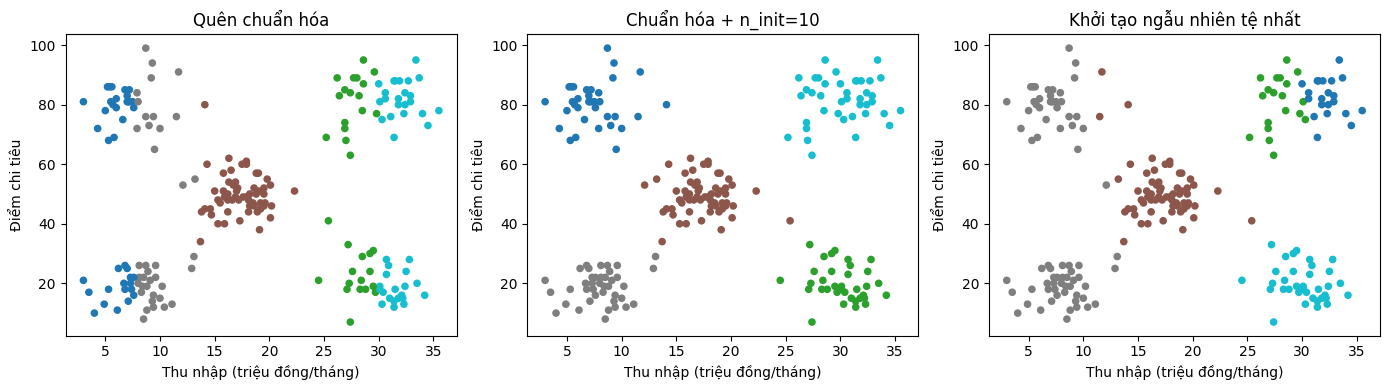

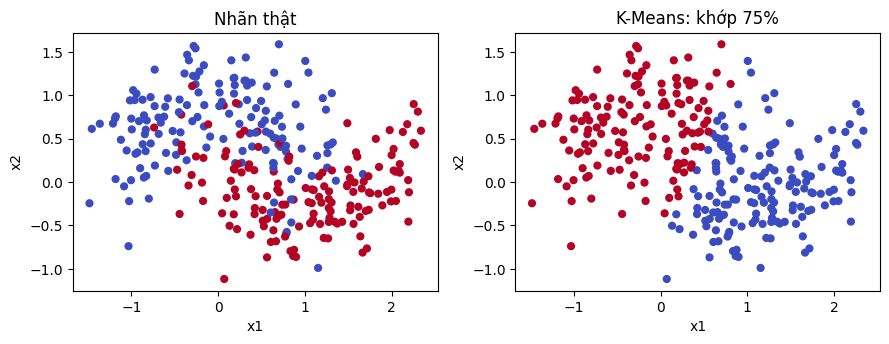

In [4]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

df = pd.read_csv(tep_du_lieu("khach_hang.csv"))
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)
# Bẫy 1: thay đơn vị thành nghìn đồng nhưng quên chuẩn hóa.
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] /= 1000
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  ({t[0]:5.1f}, {t[1]:5.1f})")
print()
ket, mo_hinh_ngau_nhien = [], []
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1, random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
    mo_hinh_ngau_nhien.append(km)
print("Bay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket = sorted(ket)
print(" ", ket[:10])
print(" ", ket[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f"  Voi n_init=10: inertia {tot.inertia_:.1f}\n")
tr = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan == tr["nhan"]).mean()
print(f"Bay 3: hai vang trang, ty le khop nhan that {max(khop, 1 - khop):.4f}")
te_nhat = max(mo_hinh_ngau_nhien, key=lambda m: m.inertia_)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, labels, title in zip(axes, [km_tho.labels_, tot.labels_, te_nhat.labels_],
                           ["Quên chuẩn hóa", "Chuẩn hóa + n_init=10", "Khởi tạo ngẫu nhiên tệ nhất"]):
    ax.scatter(X.thu_nhap, X.diem_chi_tieu, c=labels, cmap="tab10", s=20)
    ax.set(xlabel="Thu nhập (triệu đồng/tháng)", ylabel="Điểm chi tiêu", title=title)
fig.tight_layout()
plt.savefig(thu_muc_hinh / "bay_chuan_hoa_khoi_tao.png", dpi=150)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, labels, title in zip(axes, [tr.nhan, nhan], ["Nhãn thật", "K-Means: khớp 75%"]):
    ax.scatter(tr.x1, tr.x2, c=labels, cmap="coolwarm", s=24)
    ax.set(xlabel="x1", ylabel="x2", title=title)
    ax.set_aspect("equal")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "bay_hai_vang_trang.png", dpi=150)
plt.show()


## Mục 6 — Nén màu ảnh

Anh 427 x 640, co 273280 diem anh, 96615 mau

 K  so bit moi diem  nho hon  sai lech trung binh
  4       2           12.0 lan     17.41 muc sang
 16       4            6.0 lan      7.97 muc sang


 64       6            4.0 lan      4.54 muc sang


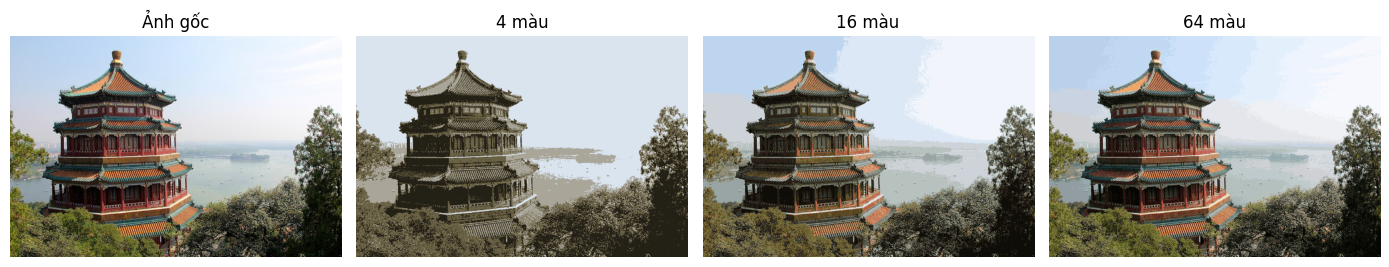

In [5]:
from pathlib import Path

# Tìm data/ từ thư mục Lab hoặc code/; chấp nhận CSV tải thẳng lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "khach_hang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Thiếu {ten}. Hãy giữ data/ hoặc tải CSV vào thư mục hiện tại trên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.datasets import load_sample_image
anh = load_sample_image("china.jpg")
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau\n")
rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]
print(" K  so bit moi diem  nho hon  sai lech trung binh")
anh_nen = {}
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f" {k:2d}       {bit}           {24 / bit:4.1f} lan     {sai:5.2f} muc sang")
    anh_nen[k] = moi.reshape(cao, rong, 3)
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, a, title in zip(axes, [anh, *anh_nen.values()], ["Ảnh gốc", "4 màu", "16 màu", "64 màu"]):
    ax.imshow(a)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.savefig(thu_muc_hinh / "nen_mau_so_sanh.png", dpi=150)
plt.show()
